In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from plots import *
from helper import *

In [2]:
df_prices = pd.read_csv("C:/Users/redli/OneDrive/Desktop/classic ml tasks/regression/Hourly_Gasoline_Prices.csv")
df_fuel_st_info = pd.read_csv(r"C:\Users\redli\OneDrive\Desktop\classic ml tasks\regression\Fuel_Station_Information.csv")

In [3]:
df_full_eda = pd.merge(df_prices, df_fuel_st_info, how = "inner", on = "Id")
df_full_eda.head(30)

,Id,isSelf,Price,Date,Fuel_station_manager,Petrol_company,Type,Station_name,City,Latitude,Longitudine
0,51169,1,1.943,2022-01-01 11:45:53,AURA PETROLSERVICE S.N.C. DI LANZA BRUNO & C.,Api-Ip,Autostradale,BAUDUCCHI OVEST,MONCALIERI,44.977978,7.700216
1,44566,1,1.725,2022-01-02 11:15:08,BOVE SOCIETA' A RESPONSABILITA' LIMITATA SEMPL...,Esso,Stradale,EASY,GALLIPOLI,40.059118,18.032323
2,44566,0,1.775,2022-01-02 11:15:08,BOVE SOCIETA' A RESPONSABILITA' LIMITATA SEMPL...,Esso,Stradale,EASY,GALLIPOLI,40.059118,18.032323
3,20026,1,1.729,2022-01-02 11:27:01,FIARDI TRADING - SOCIETA' A RESPONSABILITA' LI...,Api-Ip,Stradale,IP,CAMPOMARINO,41.938508,15.076976
4,12494,0,1.559,2022-01-02 12:07:25,BUSSINELLO S.R.L.,Pompe Bianche,Stradale,Impianto Verona Petroli - San Bonifacio,SAN BONIFACIO,45.386059,11.273766
5,12494,1,1.559,2022-01-02 12:07:25,BUSSINELLO S.R.L.,Pompe Bianche,Stradale,Impianto Verona Petroli - San Bonifacio,SAN BONIFACIO,45.386059,11.273766
6,37593,0,1.789,2022-01-02 12:36:25,CARBURANTI PALAZZO S.N.C.,Ies,Stradale,CARBURANTI PALAZZO SNC,BARANELLO,41.516827,14.594655
7,37593,1,1.789,2022-01-02 12:36:25,CARBURANTI PALAZZO S.N.C.,Ies,Stradale,CARBURANTI PALAZZO SNC,BARANELLO,41.516827,14.594655
8,50047,0,1.879,2022-01-02 14:20:37,DI BENEDETTO MARIA AGATA,SP Energia Siciliana,Stradale,stzione di servizio Di Benedetto Maria Agata,VENTIMIGLIA DI SICILIA,37.920051,13.565093
9,52185,0,1.800,2022-01-02 17:25:08,PIRA GIANPAOLO,Q8,Stradale,PIRA GIANPAOLO,BITTI,40.476894,9.382334


In [4]:
df_full_eda.isna().sum()

Id                        0
isSelf                    0
Price                     0
Date                      0
Fuel_station_manager      0
Petrol_company            0
Type                      0
Station_name            253
City                    226
Latitude                504
Longitudine             504
dtype: int64

In [5]:
df_full_eda.shape

(2451429, 11)

In [6]:
df_full_eda["Fuel_station_manager"] = df_full_eda["Fuel_station_manager"].where(
df_full_eda["Fuel_station_manager"].map(df_full_eda["Fuel_station_manager"].value_counts()) >= 20, "Other")
df_full_eda["City"] = df_full_eda["City"].fillna("MISSING")
df_full_eda["City"] = df_full_eda["City"].where(df_full_eda["City"].map(df_full_eda["City"].value_counts()) >= 20, "Other") 
df_full_eda["City"].value_counts()

City
ROMA           89952
MILANO         28743
PALERMO        22077
TORINO         20608
NAPOLI         19187
               ...  
ROCCAMENA         20
CAPOVALLE         20
GRAFFIGNANO       20
BORGO PACE        20
PIETRELCINA       20
Name: count, Length: 5249, dtype: int64

In [7]:
df_full_eda["DateTime"] = pd.to_datetime(df_full_eda["Date"])
df_full_eda["Date"] = df_full_eda["DateTime"].apply(lambda x: x.date())
df_full_eda["Date"] = pd.to_datetime(df_full_eda["Date"])
df_full_eda["Date"] = df_full_eda["Date"].dt.dayofyear
df_full_eda["Time"] = df_full_eda["DateTime"].apply(lambda x: x.time())
df_full_eda["Time"] = df_full_eda["Time"].apply(lambda x: x.hour*60 + x.minute)

In [259]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import OrdinalEncoder, TargetEncoder, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer, KNNImputer
from category_encoders import CountEncoder

In [260]:
base_line = Pipeline(
                         [
                           ("fill_na_knn", ColumnTransformer(
                                                              [
                                                                ("fill_na_city", SimpleImputer(strategy="constant", fill_value = "Missing"), ["City"]),
                                                                ("fill_na_cords", KNNImputer(n_neighbors=10), ["Latitude", "Longitudine"]),
                                                              ],
                                                              remainder = "passthrough", verbose_feature_names_out=False
                                                            )
                           ),
                           ("transformer", ColumnTransformer(
                                                              [
                                                                ("drop_date", "drop", ["DateTime"]),
                                                                ("city_encoder", CountEncoder(normalize=True, handle_unknown=0, handle_missing="value"), ["City"]),
                                                                ("manager_ecoder", TargetEncoder(smooth='auto', cv=5), ["Fuel_station_manager"]), 
                                                                ("company_encoder", TargetEncoder(smooth='auto', cv=5), ["Petrol_company"]),
                                                                ("type_encoder", OneHotEncoder(drop = "first", sparse_output=False), ["Type"]),
                                                              ],
                                                              remainder = "passthrough", verbose_feature_names_out=False
                                                             )
                           ),
                           ("scaler", "passthrough"   
                           )
                          ]
                         ) 
base_line.set_output(transform = "pandas")

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('fill_na_knn', ...), ('transformer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('fill_na_city', ...), ('fill_na_cords', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature_names_o

In [261]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate, train_test_split
from sklearn.dummy import DummyRegressor
from lightgbm import LGBMRegressor

In [262]:
X_train, X_test, y_train, y_test = train_test_split(df_full_eda.drop(["Station_name", "Price"], axis=1), df_full_eda["Price"] ,test_size = 0.2, random_state=42)
cv = TimeSeriesSplit(n_splits = 5)

In [263]:
base_line.steps.append(("model", DummyRegressor()))
base_line

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('fill_na_knn', ...), ('transformer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('fill_na_city', ...), ('fill_na_cords', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature_names_o

In [264]:
metrics = ["neg_mean_squared_error",  "neg_mean_absolute_error", "r2"]
cal_metrics_dummy = cross_validate(base_line, X_train, y_train, scoring = metrics, cv = cv, return_train_score=True, n_jobs=-1)

In [265]:
ColumnTransformer([("scaler", StandardScaler(), ["Price", "Date", "Latitude", "Longitudine", "Time"])])

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('scaler', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""

In [266]:
def metrics_calculate(cal_metrics):
    metrics = dict(list(cal_metrics.copy().items())[2:])
    for name, metric in metrics.items():
        mean_metrics = np.mean(metric)
        metrics[name] = round(mean_metrics, 4)
        print(f'{name} - {mean_metrics:.6f}')
    metrics["test_neg_root_mean_squared_error"] = (-1)*np.sqrt(-metrics["test_neg_mean_squared_error"])
    metrics["train_neg_root_mean_squared_error"] = (-1)*np.sqrt(-metrics["train_neg_mean_squared_error"])
    metrics = dict(metrics)
    res_metrics = {}
    print("--------------------------------------------------------")
    for name, mean_metrics in metrics.items():
        if len(name) > 15:
            name = "cut_" + name
            res_metrics[name] = float(mean_metrics) + 1
        else: 
            res_metrics[name] = float(mean_metrics)
        print(f'{name} - {res_metrics[name]:.6f}')
    return res_metrics

In [249]:
res_metrics_dummy = metrics_calculate(cal_metrics_dummy)

test_neg_mean_squared_error - -0.031848
train_neg_mean_squared_error - -0.031942
test_neg_mean_absolute_error - -0.146375
train_neg_mean_absolute_error - -0.146455
test_r2 - -0.000001
train_r2 - 0.000000
--------------------------------------------------------
cut_test_neg_mean_squared_error - 0.968200
cut_train_neg_mean_squared_error - 0.968100
cut_test_neg_mean_absolute_error - 0.853600
cut_train_neg_mean_absolute_error - 0.853500
test_r2 - -0.000000
train_r2 - 0.000000
cut_test_neg_root_mean_squared_error - 0.821674
cut_train_neg_root_mean_squared_error - 0.821394


<Axes: >

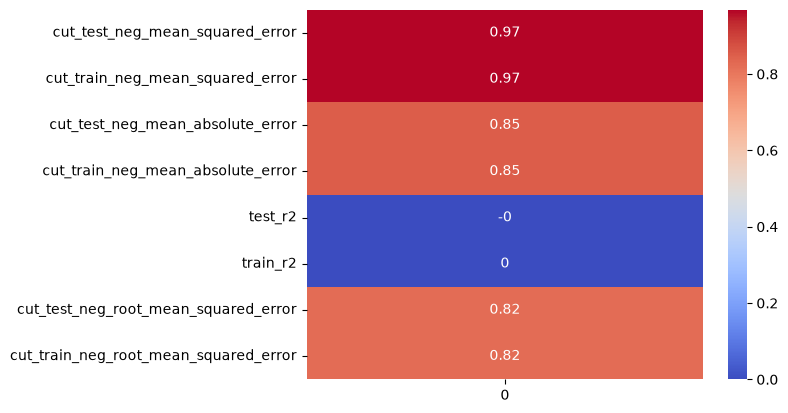

In [250]:
sns.heatmap(pd.Series(res_metrics_dummy).to_frame(), annot=True, cmap='coolwarm')

In [224]:
base_line.set_params(model=LGBMRegressor())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('fill_na_knn', ...), ('transformer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('fill_na_city', ...), ('fill_na_cords', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature_names_o

In [251]:
metrics = ["neg_mean_squared_error",  "neg_mean_absolute_error", "r2"]
cal_metrics_lgbm = cross_validate(base_line, X_train, y_train, scoring = metrics, cv = cv, return_train_score=True, n_jobs=-1)

In [252]:
res_metrics_lgbm = metrics_calculate(cal_metrics_lgbm)

test_neg_mean_squared_error - -0.005194
train_neg_mean_squared_error - -0.004768
test_neg_mean_absolute_error - -0.045878
train_neg_mean_absolute_error - -0.043983
test_r2 - 0.836919
train_r2 - 0.850744
--------------------------------------------------------
cut_test_neg_mean_squared_error - 0.994800
cut_train_neg_mean_squared_error - 0.995200
cut_test_neg_mean_absolute_error - 0.954100
cut_train_neg_mean_absolute_error - 0.956000
test_r2 - 0.836900
train_r2 - 0.850700
cut_test_neg_root_mean_squared_error - 0.927889
cut_train_neg_root_mean_squared_error - 0.930718


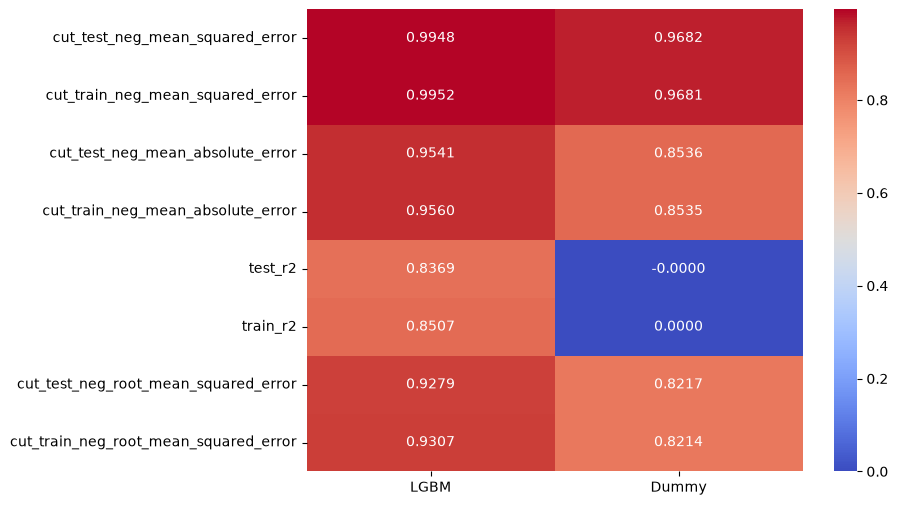

In [257]:
df_metrics = pd.DataFrame({"LGBM" : pd.Series(res_metrics_lgbm), "Dummy" : pd.Series(res_metrics_dummy)})

plt.figure(figsize=(8, 6))
sns.heatmap(df_metrics, annot=True, cmap='coolwarm', fmt='.4f')
plt.show()

In [258]:
dif_lgbm_dummy = {}
for name, metrics in res_metrics_lgbm.items():
    if len(name) > 15:
        dif_lgbm_dummy[name] = res_metrics_lgbm[name] - res_metrics_dummy[name]
        
dif_lgbm_dummy

{'cut_test_neg_mean_squared_error': 0.026600000000000068,
 'cut_train_neg_mean_squared_error': 0.027100000000000013,
 'cut_test_neg_mean_absolute_error': 0.10049999999999992,
 'cut_train_neg_mean_absolute_error': 0.10249999999999992,
 'cut_test_neg_root_mean_squared_error': 0.10621451949199023,
 'cut_train_neg_root_mean_squared_error': 0.10932367869216242}

<Axes: >

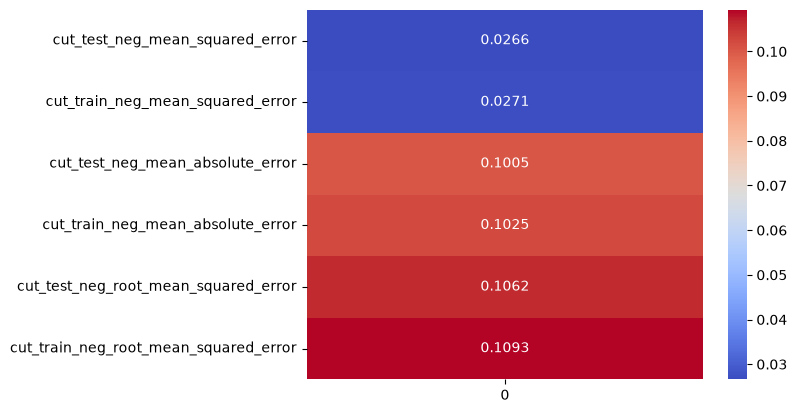

In [256]:
sns.heatmap(pd.Series(dif_lgbm_dummy).to_frame(), annot=True, cmap='coolwarm', fmt='.4f')

In [230]:
print(pd.Series(res_metrics_lgbm))
print(pd.Series(res_metrics_dummy))

cut_test_neg_mean_squared_error          0.994800
cut_train_neg_mean_squared_error         0.995200
cut_test_neg_mean_absolute_error         0.954200
cut_train_neg_mean_absolute_error        0.956000
test_r2                                  0.837200
train_r2                                 0.851100
cut_test_neg_root_mean_squared_error     1.072111
cut_train_neg_root_mean_squared_error    1.069282
dtype: float64
cut_test_neg_mean_squared_error          0.968200
cut_train_neg_mean_squared_error         0.968100
cut_test_neg_mean_absolute_error         0.853600
cut_train_neg_mean_absolute_error        0.853500
test_r2                                 -0.000000
train_r2                                 0.000000
cut_test_neg_root_mean_squared_error     1.178326
cut_train_neg_root_mean_squared_error    1.178606
dtype: float64
